# Модуль 1 — детекция активного горения (AF)

Вход: AF-чип 256x256 @ 375 м (VIIRS I1-I5 + solar/sensor zenith + valid, плюс отдельный AUX-слой: landcover, dem, t2m, rh2m, wind_speed).

Выход: бинарная маска (1 = природное горение, 0 = всё прочее, включая техногенные термоаномалии).

Метрика: `F1_af`, микро-усреднение TP/FP/FN по всем чипам, вес 0.35 в общем `Score`.

Модель: LightGBM на контекстных пиксельных признаках (см. секцию 5) — это тот же принцип, что и в операционных алгоритмах активного огня (VIIRS/MODIS AF), только порог заменён на обученный классификатор с богатым контекстом (локальный фон, метеоусловия, тип подстилающей поверхности), что должно ощутимо поднять F1 относительно фиксированного порога.

## 0. Настройка

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import uniform_filter
from tqdm.auto import tqdm

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

Ноутбук самодостаточный — код `src/dataio.py`, `src/rle.py`, `src/metrics.py` встроен прямо сюда (см. следующие 3 ячейки), поэтому запуск в Colab работает при загрузке одного `.ipynb`-файла, без остального репозитория рядом.

In [2]:
# === встроено из src/dataio.py - не редактировать здесь, правьте src/dataio.py и пересоберите ноутбук через build_notebooks.py ===
"""Chip readers for the КосмоХакатон fire-monitoring dataset.

Disk on the dev machine is essentially full, so `TarChipSource` reads every
GeoTIFF straight out of `fire-train-renamed.tar` into memory (via
rasterio.io.MemoryFile) and never extracts anything to disk. `DirChipSource`
is the same interface for a plain extracted folder, for when the organizers'
test set turns out to ship as loose files instead of a tar - swap the source,
keep every notebook/inference cell unchanged.

Band names are read from each GeoTIFF's own band descriptions (they're
embedded in the files), not hardcoded from the case statement PDF, so this
keeps working even if a channel gets reordered.
"""
from __future__ import annotations

import io
import tarfile
from pathlib import Path
from typing import Iterable

import numpy as np
import pandas as pd
import rasterio
from rasterio.io import MemoryFile


class _ChipSourceBase:
    def _read_bytes(self, relpath: str) -> bytes:
        raise NotImplementedError

    def close(self) -> None:
        """No-op by default; TarChipSource overrides this to close its tarfile handle."""

    def __enter__(self):
        return self

    def __exit__(self, *exc) -> None:
        self.close()

    def read_named(self, relpath: str) -> dict:
        """Multi-band GeoTIFF -> dict keyed by band description, plus '_bands' (C,H,W),
        '_names' (tuple) and '_profile' (rasterio profile, has crs/transform/nodata)."""
        raw = self._read_bytes(relpath)
        with MemoryFile(raw) as mem, mem.open() as src:
            names = src.descriptions
            arr = src.read()
            profile = src.profile
        out = {"_bands": arr, "_names": tuple(names), "_profile": profile}
        for i, name in enumerate(names):
            if name:
                out[name] = arr[i]
        return out

    def read_csv(self, relpath: str) -> pd.DataFrame:
        return pd.read_csv(io.BytesIO(self._read_bytes(relpath)))

    def meta(self, kind: str) -> pd.DataFrame:
        return self.read_csv(f"{kind}/meta.csv")

    def chip_ids(self, kind: str) -> list[str]:
        return self.meta(kind)["chip_id"].tolist()

    def _try_load_mask(self, relpath: str) -> tuple[np.ndarray | None, float | None]:
        """Test chips ship with no mask (that's what we predict) - returns (None, None)
        instead of raising, so load_af/load_bs work unchanged on train, val AND test."""
        try:
            mask_raw = self.read_named(relpath)
        except FileNotFoundError:
            return None, None
        return mask_raw["_bands"][0], mask_raw["_profile"].get("nodata")

    def load_af(self, chip_id: str) -> dict:
        viirs = self.read_named(f"af/viirs/{chip_id}_VIIRS_I1-I5.tif")
        aux = self.read_named(f"af/aux/{chip_id}_AUX.tif")
        mask, mask_nodata = self._try_load_mask(f"af/masks/{chip_id}_MASK.tif")
        return {
            "chip_id": chip_id,
            "viirs": viirs,
            "aux": aux,
            "mask": mask,
            "mask_nodata": mask_nodata,
        }

    def load_bs(self, chip_id: str) -> dict:
        s2_pre = self.read_named(f"bs/sentinel2_pre/{chip_id}_Sentinel-2_pre.tif")
        s2_post = self.read_named(f"bs/sentinel2_post/{chip_id}_Sentinel-2_post.tif")
        s1_pre = self.read_named(f"bs/sentinel1_pre/{chip_id}_Sentinel-1_pre.tif")
        s1_post = self.read_named(f"bs/sentinel1_post/{chip_id}_Sentinel-1_post.tif")
        aux = self.read_named(f"bs/aux/{chip_id}_AUX.tif")
        mask, mask_nodata = self._try_load_mask(f"bs/masks/{chip_id}_MASK.tif")
        return {
            "chip_id": chip_id,
            "s2_pre": s2_pre,
            "s2_post": s2_post,
            "s1_pre": s1_pre,
            "s1_post": s1_post,
            "aux": aux,
            "mask": mask,
            "mask_nodata": mask_nodata,
        }


class TarChipSource(_ChipSourceBase):
    """Reads chips directly out of fire-train-renamed.tar, no extraction to disk."""

    def __init__(self, tar_path: str | Path, root: str = "train"):
        self.tar_path = str(tar_path)
        self.root = root
        self._tar = tarfile.open(self.tar_path)

    def _read_bytes(self, relpath: str) -> bytes:
        member = f"{self.root}/{relpath}"
        try:
            buf = self._tar.extractfile(member)
        except KeyError:
            # tarfile raises KeyError (not FileNotFoundError) for a missing member -
            # normalize it so callers (e.g. _try_load_mask) can catch one exception
            # type regardless of which ChipSource they're using.
            raise FileNotFoundError(member) from None
        if buf is None:
            raise FileNotFoundError(member)
        return buf.read()

    def close(self) -> None:
        self._tar.close()


class DirChipSource(_ChipSourceBase):
    """Same interface as TarChipSource, for an already-extracted directory
    (e.g. the organizers' --data-dir at inference time)."""

    def __init__(self, root_dir: str | Path):
        self.root_dir = Path(root_dir)

    def _read_bytes(self, relpath: str) -> bytes:
        path = self.root_dir / relpath
        return path.read_bytes()


def nodata_to_ignore(mask: np.ndarray, nodata: float | None) -> np.ndarray:
    """Boolean valid-pixel mask (True = usable) from a mask array + its nodata value."""
    if nodata is None:
        return np.ones_like(mask, dtype=bool)
    return mask != nodata


def iter_chips(source: _ChipSourceBase, kind: str, chip_ids: Iterable[str] | None = None):
    """Yield load_af()/load_bs() dicts for every chip_id (or all chips if None)."""
    loader = source.load_af if kind == "af" else source.load_bs
    ids = list(chip_ids) if chip_ids is not None else source.chip_ids(kind)
    for chip_id in ids:
        yield loader(chip_id)


In [3]:
# === встроено из src/rle.py - не редактировать здесь, правьте src/rle.py и пересоберите ноутбук через build_notebooks.py ===
"""RLE encode/decode matching the КосмоХакатон submission.csv spec.

Pixel numbering is row-major (left-to-right, top-to-bottom), 1-indexed.
Runs are reported in ascending start order and never overlap or touch,
which is exactly what run-length-encoding a boolean mask gives you for free.
"""
from __future__ import annotations

import numpy as np
import pandas as pd


def encode_rle(mask: np.ndarray) -> str:
    """2D boolean/0-1 array -> RLE string ("start len start len ..."), '' if empty."""
    flat = np.asarray(mask, dtype=bool).ravel(order="C")
    if not flat.any():
        return ""
    padded = np.concatenate(([0], flat.astype(np.int8), [0]))
    diffs = np.diff(padded)
    starts_0idx = np.flatnonzero(diffs == 1)
    ends_k = np.flatnonzero(diffs == -1)
    lengths = ends_k - starts_0idx
    starts_1idx = starts_0idx + 1
    return " ".join(f"{s} {l}" for s, l in zip(starts_1idx, lengths))


def decode_rle(rle, shape: tuple[int, int]) -> np.ndarray:
    """RLE string + (H, W) -> boolean mask.

    An empty mask round-trips through CSV as an empty field, which pandas reads back
    as NaN (float) rather than "" - this is also how the organizers' own
    sample_submission.csv represents "no pixels of this class", so NaN/None are treated
    the same as an empty string here rather than as errors.
    """
    mask = np.zeros(shape[0] * shape[1], dtype=bool)
    if rle is None or (isinstance(rle, float) and np.isnan(rle)):
        rle = ""
    rle = str(rle).strip()
    if rle:
        nums = list(map(int, rle.split()))
        for start, length in zip(nums[0::2], nums[1::2]):
            s0 = start - 1
            mask[s0 : s0 + length] = True
    return mask.reshape(shape, order="C")


def submission_row(chip_id: str, class_id: int, mask: np.ndarray) -> dict:
    return {"chip_id": chip_id, "class_id": int(class_id), "rle": encode_rle(mask)}


def validate_submission(df: pd.DataFrame, sample_submission: pd.DataFrame) -> list[str]:
    """Structural checks against the shipped sample_submission.csv. Empty list == OK."""
    problems = []
    required = set(zip(sample_submission["chip_id"], sample_submission["class_id"]))
    got = set(zip(df["chip_id"], df["class_id"]))
    missing = required - got
    extra = got - required
    if missing:
        problems.append(f"missing {len(missing)} (chip_id, class_id) pairs, e.g. {list(missing)[:5]}")
    if extra:
        problems.append(f"unexpected {len(extra)} (chip_id, class_id) pairs, e.g. {list(extra)[:5]}")
    # NaN in "rle" is NOT an error: an empty mask round-trips through to_csv/read_csv as
    # an empty field, which pandas parses as NaN - decode_rle() treats it as "" on purpose,
    # matching how the organizers' own sample_submission.csv represents an empty mask.
    if df.duplicated(subset=["chip_id", "class_id"]).any():
        problems.append("duplicate (chip_id, class_id) rows found")
    return problems


def validate_submission_full(
    df: pd.DataFrame,
    sample_submission: pd.DataFrame,
    chip_shapes: dict[str, tuple[int, int]],
) -> list[str]:
    """Structural checks plus per-chip overlap/out-of-bounds decoding checks."""
    problems = validate_submission(df, sample_submission)
    for chip_id, group in df.groupby("chip_id"):
        shape = chip_shapes.get(chip_id)
        if shape is None:
            continue
        total = np.zeros(shape, dtype=np.uint8)
        for _, row in group.iterrows():
            try:
                m = decode_rle(row["rle"], shape)
            except Exception as e:  # noqa: BLE001 - want the chip_id in the message
                problems.append(f"{chip_id}/{row['class_id']}: RLE decode failed ({e})")
                continue
            total += m.astype(np.uint8)
        if (total > 1).any():
            problems.append(f"{chip_id}: overlapping masks between classes")
    return problems


In [4]:
# === встроено из src/metrics.py - не редактировать здесь, правьте src/metrics.py и пересоберите ноутбук через build_notebooks.py ===
"""Competition score, computed exactly like the organizers compute it:
pixels from every chip are pooled into one confusion matrix per class
(micro-averaging) *before* precision/recall/F1/IoU are derived - not
averaged per-chip and then across chips.

Score = 0.35 * F1_af + 0.35 * IoU_burn + 0.30 * mIoU_sev
"""
from __future__ import annotations

import numpy as np


class ConfusionAccumulator:
    """Pools TP/FP/FN across an arbitrary number of update() calls (= chips)."""

    def __init__(self, classes: tuple[int, ...]):
        self.classes = tuple(classes)
        self.tp = {c: 0 for c in self.classes}
        self.fp = {c: 0 for c in self.classes}
        self.fn = {c: 0 for c in self.classes}

    def update(self, pred: np.ndarray, true: np.ndarray, valid: np.ndarray | None = None) -> None:
        if valid is None:
            valid = np.ones_like(true, dtype=bool)
        for c in self.classes:
            p = (pred == c) & valid
            t = (true == c) & valid
            self.tp[c] += int(np.sum(p & t))
            self.fp[c] += int(np.sum(p & ~t))
            self.fn[c] += int(np.sum(~p & t))

    def iou(self, c: int) -> float:
        tp, fp, fn = self.tp[c], self.fp[c], self.fn[c]
        denom = tp + fp + fn
        return 1.0 if denom == 0 else tp / denom

    def precision_recall_f1(self, c: int) -> tuple[float, float, float]:
        tp, fp, fn = self.tp[c], self.fp[c], self.fn[c]
        if tp + fp == 0 and tp + fn == 0:
            return 1.0, 1.0, 1.0
        precision = tp / (tp + fp) if (tp + fp) else 0.0
        recall = tp / (tp + fn) if (tp + fn) else 0.0
        f1 = 0.0 if precision + recall == 0 else 2 * precision * recall / (precision + recall)
        return precision, recall, f1


def binarize_burn(mask: np.ndarray) -> np.ndarray:
    """BS mask (0/1/2/3) -> binary burned/not-burned mask, for IoU_burn."""
    return (mask >= 1).astype(np.uint8)


def f1_af(acc: ConfusionAccumulator) -> float:
    return acc.precision_recall_f1(1)[2]


def iou_burn(acc_binary: ConfusionAccumulator) -> float:
    """acc_binary must have been fed binarize_burn() masks with classes=(1,)."""
    return acc_binary.iou(1)


def miou_severity(acc_sev: ConfusionAccumulator) -> float:
    """acc_sev must have been fed the raw 0..3 masks with classes=(1, 2, 3)."""
    return sum(acc_sev.iou(c) for c in (1, 2, 3)) / 3


def score(f1_af_value: float, iou_burn_value: float, miou_sev_value: float) -> float:
    return 0.35 * f1_af_value + 0.35 * iou_burn_value + 0.30 * miou_sev_value


## 0. Данные: загрузка с Kaggle

Датасет уже опубликован: https://www.kaggle.com/datasets/shotme/cosmohack2026
(публичный, `shotme/cosmohack2026` уже подставлен ниже) — просто выполняйте
ячейки по порядку, ничего менять не нужно.

Ноутбук рассчитан на запуск в Colab/Kaggle Notebook с GPU. Данные тянутся через
`kagglehub.dataset_download` — ничего вручную скачивать/распаковывать не нужно.
Загрузчик ниже сам определяет, лежит ли `fire-{train,test}-renamed` на Kaggle
как исходный `.tar` или как уже распакованная папка (Data Explorer Kaggle
иногда показывает архивы «развёрнутыми» в дереве) — работает в обоих случаях.

**Тест уже выложен** (`fire-test-renamed`, 180 AF + 89 BS чипов, без масок —
их и предсказываем) и добавлен новой версией того же Kaggle-датасета.
`resolve_test_source(DATASET_DIR)` в ячейках инференса подхватывает его точно
так же, как `resolve_train_source` — train. `test/sample_submission.csv` и
`test/meta.csv` лежат в корне тестового архива (не под `af/`/`bs/`, в отличие
от `train/af/meta.csv` и `train/bs/meta.csv`) — читаются через
`test_source.read_csv("sample_submission.csv")`.

**Авторизация нужна обязательно** — Kaggle API требует ключ даже для скачивания
публичных датасетов (проверено: без него `kagglehub.dataset_download` падает
с ошибкой credentials). Самый чистый вариант под Colab — **Colab Secrets**,
делается один раз на весь Google-аккаунт и работает потом в любом ноутбуке
без единой правки кода:

1. В Colab слева — значок 🔑 (Secrets) → **Add new secret**.
2. Добавить `KAGGLE_USERNAME` = ваш ник на Kaggle.
3. Добавить `KAGGLE_KEY` = API-ключ (kaggle.com → Settings → API →
   **Create New Token** — скачается `kaggle.json`, ключ и username там же).
4. Включить переключатель **Notebook access** у обоих секретов.

После этого ячейка ниже отработает сама. `kagglehub.login()` для Colab **не
использовать** — его виджет не блокирует выполнение ячейки, из-за чего
«Run All» уезжает вперёд к скачиванию раньше, чем токен успевает
сохраниться.


In [5]:
KAGGLE_DATASET_HANDLE = "shotme/cosmohack2026"
_LOCAL_DEV_PATH = r"..\..\Мониторинг DATA\Мониторинг DATA"  # только для локальной разработки

import os

if os.path.isdir(_LOCAL_DEV_PATH):
    # локальная машина разработчика - без похода в сеть (данные уже лежат на диске)
    DATASET_DIR = _LOCAL_DEV_PATH
    print("Найдены локальные данные - используем их:", DATASET_DIR)
else:
    # Colab / любая другая машина - тянем публичный датасет с Kaggle.
    # Нужны Kaggle-credentials, даже для публичных датасетов (см. markdown выше) -
    # в Colab это делается один раз через Secrets (значок ключа слева), без правок кода.
    import kagglehub
    try:
        DATASET_DIR = kagglehub.dataset_download(KAGGLE_DATASET_HANDLE)
    except Exception as e:
        raise RuntimeError(
            "Не удалось скачать датасет с Kaggle - похоже, не настроены credentials. "
            "В Colab: значок ключа (Secrets) слева -> Add new secret -> добавить "
            "KAGGLE_USERNAME и KAGGLE_KEY (взять на kaggle.com -> Settings -> API -> "
            "Create New Token) -> включить Notebook access для обоих -> перезапустить "
            "эту ячейку. Подробности - README.md в solution/."
        ) from e
    print("Датасет с Kaggle загружен в:", DATASET_DIR)


def _resolve_source(dataset_dir, kind, source_classes):
    """kind = 'train' или 'test'. fire-{kind}-renamed на Kaggle может быть как исходным
    .tar, так и уже распакованной папкой (зависит от того, разворачивает ли Kaggle архив
    при показе/скачивании) - подхватываем оба варианта без ручных правок."""
    TarChipSource, DirChipSource = source_classes
    tar_path = os.path.join(dataset_dir, f"fire-{kind}-renamed.tar")
    if os.path.isfile(tar_path):
        print(f"Источник {kind}: tar-архив ->", tar_path)
        return TarChipSource(tar_path, root=kind)
    for candidate in (
        os.path.join(dataset_dir, f"fire-{kind}-renamed", kind),
        os.path.join(dataset_dir, kind),
    ):
        if os.path.isdir(candidate):
            print(f"Источник {kind}: распакованная папка ->", candidate)
            return DirChipSource(candidate)
    raise FileNotFoundError(
        f"Не нашли ни {tar_path}, ни распакованную папку {kind}/ внутри {dataset_dir} - "
        "проверьте структуру датасета на Kaggle (Data Explorer)."
    )


def resolve_train_source(dataset_dir):
    return _resolve_source(dataset_dir, "train", (TarChipSource, DirChipSource))


def resolve_test_source(dataset_dir):
    """Тестовые чипы (fire-test-renamed) - без масок, plus test/sample_submission.csv
    и test/meta.csv лежат в корне (не под af/ или bs/, в отличие от train)."""
    return _resolve_source(dataset_dir, "test", (TarChipSource, DirChipSource))


100%|██████████| 3.00G/3.00G [03:08<00:00, 17.1MB/s]


Extracting files...
Датасет с Kaggle загружен в: /root/.cache/kagglehub/datasets/shotme/cosmohack2026/versions/2


## Важно: где обучать

`RUN_HEAVY_TRAINING` ниже управляет тяжёлыми ячейками (обучение LightGBM /
U-Net). На локальной машине держим его `False` — здесь нет GPU и мало места на
диске. Ставим `True` только на Colab (Runtime → Change runtime type → GPU) или
Kaggle Notebook (Settings → Accelerator → GPU T4x2/P100). Всё остальное
(feature engineering, EDA, быстрые smoke-тесты кода модели) выполняется и
локально.

In [8]:
import torch

RUN_HEAVY_TRAINING = True  # True только на Colab/Kaggle с GPU
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "| RUN_HEAVY_TRAINING:", RUN_HEAVY_TRAINING)


device: cuda | RUN_HEAVY_TRAINING: True


### Куда сохраняются веса

`/content` в Colab — эфемерная файловая система: всё в ней пропадает при
отключении рантайма (по таймауту или вручную), а обучение занимает часы —
терять веса из-за этого обидно. Поэтому чекпоинты и метаданные для
воспроизводимости (гиперпараметры, имена признаков, seed, метрика на
валидации) пишутся на Google Drive, если ноутбук выполняется в Colab, или в
локальную папку `./checkpoints` в остальных случаях (эта машина, Kaggle
Notebook и т.п.).

In [9]:
import os


def _setup_checkpoint_dir():
    try:
        from google.colab import drive
        drive.mount("/content/drive", force_remount=False)
        path = "/content/drive/MyDrive/kosmohack2026/checkpoints"
    except ImportError:
        path = os.path.join(".", "checkpoints")
    os.makedirs(path, exist_ok=True)
    return path


CHECKPOINT_DIR = _setup_checkpoint_dir()
print("Чекпоинты сохраняются в:", CHECKPOINT_DIR)


Mounted at /content/drive
Чекпоинты сохраняются в: /content/drive/MyDrive/kosmohack2026/checkpoints


In [10]:
src = resolve_train_source(DATASET_DIR)
meta_af = src.meta('af')
meta_af.head()

Источник train: распакованная папка -> /root/.cache/kagglehub/datasets/shotme/cosmohack2026/versions/2/fire-train-renamed/train


,chip_id,kind,fire_event_id,region,epsg,x_min,y_min,x_max,y_max,width,...,s1_date_pre,s1_date_post,valid_frac,cloud_frac,landcover_top,n_fire_px,burn_area_ha,sev1_px,sev2_px,sev3_px
0,AF_tr_000001,af,NaN,NaN,32637.0,384000.0,5280000.0,480000.0,5376000.0,256,...,NaN,NaN,1.0,NaN,NaN,44.0,NaN,NaN,NaN,NaN
1,AF_tr_000002,af,NaN,NaN,32637.0,384000.0,5664000.0,480000.0,5760000.0,256,...,NaN,NaN,1.0,NaN,NaN,24.0,NaN,NaN,NaN,NaN
2,AF_tr_000003,af,NaN,NaN,32637.0,480000.0,5664000.0,576000.0,5760000.0,256,...,NaN,NaN,1.0,NaN,NaN,40.0,NaN,NaN,NaN,NaN
3,AF_tr_000004,af,NaN,NaN,32637.0,384000.0,4992000.0,480000.0,5088000.0,256,...,NaN,NaN,1.0,NaN,NaN,0.0,NaN,NaN,NaN,NaN
4,AF_tr_000005,af,NaN,NaN,32637.0,384000.0,5280000.0,480000.0,5376000.0,256,...,NaN,NaN,1.0,NaN,NaN,21.0,NaN,NaN,NaN,NaN


## 1. EDA

- доля горящих пикселей и распределение `n_fire_px` по чипам (дисбаланс — экстремальный);
- разбивка по `landcover` из AUX (доля горящих пикселей на пашне/застройке — потенциальный источник техногенных срабатываний, которые модель должна научиться подавлять сама через фичу);
- визуальный осмотр чипа (I4, I4-I5, маска).

чипов всего: 420
чипов с горением: 296 без горения: 124
всего пикселей горения: 9725 из 27525120 (0.0353% пикселей)
медиана по позитивным чипам: 21.0


Text(0.5, 1.0, 'Распределение размера очага')

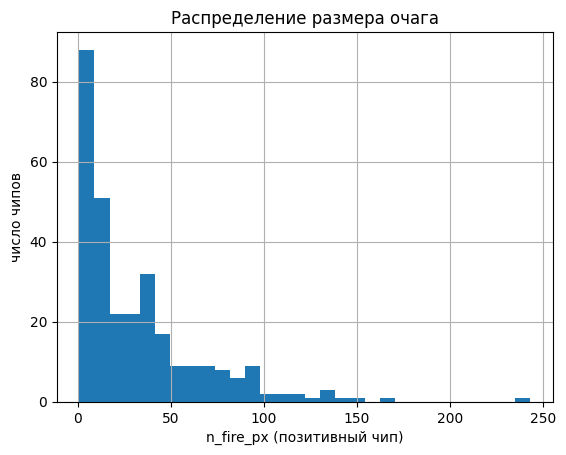

In [11]:
n_fire = meta_af['n_fire_px'].fillna(0)
print('чипов всего:', len(meta_af))
print('чипов с горением:', (n_fire > 0).sum(), 'без горения:', (n_fire == 0).sum())
print('всего пикселей горения:', int(n_fire.sum()), 'из', len(meta_af) * 256 * 256,
      f'({100 * n_fire.sum() / (len(meta_af) * 256 * 256):.4f}% пикселей)')
print('медиана по позитивным чипам:', n_fire[n_fire > 0].median())
n_fire[n_fire > 0].hist(bins=30)
plt.xlabel('n_fire_px (позитивный чип)'); plt.ylabel('число чипов'); plt.title('Распределение размера очага')

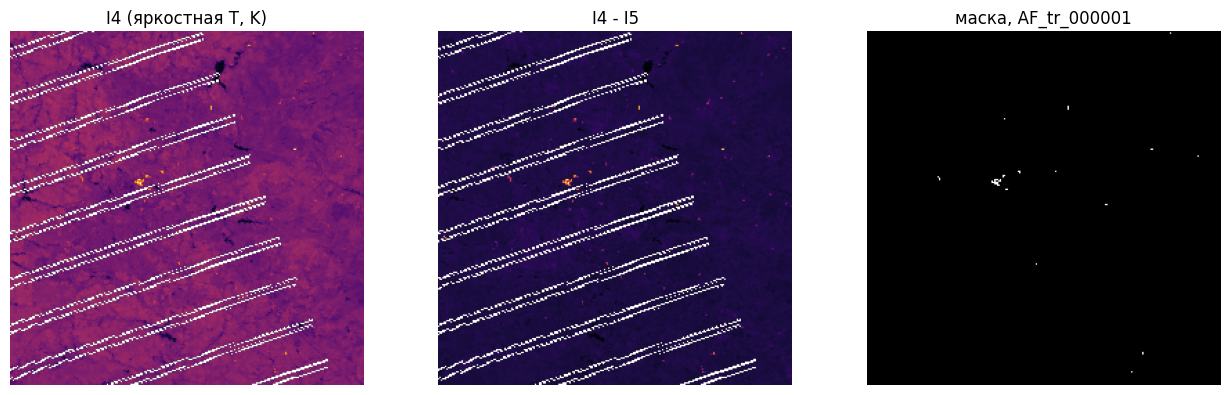

In [12]:
chip_id = meta_af.loc[meta_af['n_fire_px'] > 20, 'chip_id'].iloc[0]
sample = src.load_af(chip_id)
I4, I5 = sample['viirs']['I4'], sample['viirs']['I5']
mask = sample['mask']

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].imshow(I4, cmap='inferno'); axes[0].set_title('I4 (яркостная T, K)')
axes[1].imshow(I4 - I5, cmap='inferno'); axes[1].set_title('I4 - I5')
axes[2].imshow(mask, cmap='gray'); axes[2].set_title(f'маска, {chip_id}')
for ax in axes: ax.axis('off')
plt.tight_layout()

## 2. Baseline: контекстная детекция (яркостная температура vs фон)

Логика из постановки: пиксель — кандидат, если `I4` и `I4 - I5` одновременно превышают статистику фона в скользящем окне. Держим как контрольную точку — обученная модель ниже должна её уверенно обходить.

(np.float64(-0.5), np.float64(255.5), np.float64(255.5), np.float64(-0.5))

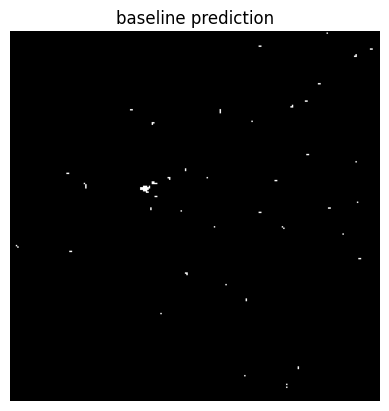

In [13]:
def baseline_af_predict(I4, I5, win=21, k_ctx=3.0):
    diff = I4 - I5
    bg_I4 = uniform_filter(I4, size=win)
    bg_diff = uniform_filter(diff, size=win)
    std_I4 = np.sqrt(np.clip(uniform_filter(I4**2, size=win) - bg_I4**2, 0, None)) + 1e-3
    std_diff = np.sqrt(np.clip(uniform_filter(diff**2, size=win) - bg_diff**2, 0, None)) + 1e-3
    cond_ctx = (I4 - bg_I4 > k_ctx * std_I4) & (diff - bg_diff > k_ctx * std_diff)
    cond_abs = I4 > 320
    return (cond_ctx | cond_abs).astype(np.uint8)

pred = baseline_af_predict(np.nan_to_num(I4, nan=280.0), np.nan_to_num(I5, nan=280.0))
plt.imshow(pred, cmap='gray'); plt.title('baseline prediction'); plt.axis('off')

## 3. Валидационный сплит

`fire_event_id` у AF-чипов пустой (`meta_af['fire_event_id'].nunique() == 0`) — группировать по нему, как в BS, нельзя. Но `acq_datetime` — всего 78 уникальных значений на 420 чипов, то есть до 9 чипов делят один и тот же пролёт спутника (общая калибровка сенсора, общая погодная картина дня). **Случайный сплит по `chip_id` пропускает чипы одного пролёта и в train, и в val одновременно** — это утечка, которая завышает валидационную метрику, не отражая обобщение на новые пожары/пролёты. Группируем по `acq_datetime`, стратифицируя по тому, встречается ли горение хотя бы в одном чипе пролёта — аналогично тому, как BS группирует по `fire_event_id`.

In [14]:
from sklearn.model_selection import train_test_split

group_has_fire = meta_af.groupby('acq_datetime')['n_fire_px'].apply(lambda s: (s.fillna(0) > 0).any())
train_groups, val_groups = train_test_split(
    group_has_fire.index, test_size=0.2, random_state=RANDOM_SEED, stratify=group_has_fire.values
)
train_ids = meta_af.loc[meta_af['acq_datetime'].isin(train_groups), 'chip_id']
val_ids = meta_af.loc[meta_af['acq_datetime'].isin(val_groups), 'chip_id']
print(len(train_ids), 'train /', len(val_ids), 'val (уникальных пролётов:', len(group_has_fire), ')')

336 train / 84 val (уникальных пролётов: 78 )


## 4. Baseline на валидации (F1_af, micro) — контрольная точка

In [15]:
acc = ConfusionAccumulator(classes=(1,))
for chip in tqdm(iter_chips(src, 'af', val_ids), total=len(val_ids), desc='baseline eval (val)'):
    I4c = np.nan_to_num(chip['viirs']['I4'], nan=280.0)
    I5c = np.nan_to_num(chip['viirs']['I5'], nan=280.0)
    valid = nodata_to_ignore(chip['mask'], chip['mask_nodata'])
    pred_c = baseline_af_predict(I4c, I5c)
    acc.update(pred_c, chip['mask'], valid=valid)

print('baseline F1_af (val, micro):', f1_af(acc))

baseline eval (val):   0%|          | 0/84 [00:00<?, ?it/s]

baseline F1_af (val, micro): 0.3576392287364197


## 5. Признаки для LightGBM (расширенные)

Физические (I1-I5, разница I4-I5) + **многомасштабный** контекстный фон (z-score в окнах 9/21/41 — мелкие техногенные горячие точки часто «горячие» локально, но сливаются с фоном на большом масштабе, и наоборот для крупных пожаров; их отношение — почти бесплатный дополнительный сигнал) + геометрия наблюдения (solar/sensor zenith, день/ночь) + **sun-glint прокси** (отношения I1/I2/I3 и средняя дневная отражательная способность — блики от воды/крыш/панелей днём дают высокую плоскую reflectance без настоящего горения) + контекст AUX (landcover, dem/t2m/rh2m/wind_speed) + **landcover-интеракции** (`z_I4 × пашня`, `z_diff × застройка` — экономят дереву сплиты на переоткрытие «горячий пиксель на пашне/в городе требует другого порога», прямая атака на названную в постановке проблему техногенных термоаномалий).

NaN в I4/I5 (полосы наблюдения) заполняются средним по чипу перед сглаживанием, чтобы NaN не расползался по соседним валидным пикселям через `uniform_filter`; I1-I3 (дневные reflectance-каналы, ночью NaN) обнуляются перед расчётом отношений.

In [16]:
AF_FEATURE_NAMES = [
    'I1', 'I2', 'I3', 'I4', 'I5', 'diff_I4_I5',
    'z_I4_w9', 'z_diff_w9',
    'z_I4_w21', 'z_diff_w21', 'bg_I4', 'bg_diff',
    'z_I4_w41', 'z_diff_w41', 'z_I4_scale_ratio',
    'solar_zenith', 'sensor_zenith', 'is_night',
    'I1_I2_ratio', 'I2_I3_ratio', 'mean_refl_day',
    'landcover', 'dem', 't2m', 'rh2m', 'wind_speed',
    'z_I4_x_cropland', 'z_diff_x_urban',
]
AF_LANDCOVER_IDX = AF_FEATURE_NAMES.index('landcover')
AF_LANDCOVER_CROPLAND_CODE = 40  # ESA WorldCover: cropland
AF_LANDCOVER_URBAN_CODE = 50     # ESA WorldCover: built-up


def _fill_nan(arr, fallback=280.0):
    if np.isnan(arr).any():
        fill = np.nanmean(arr) if not np.isnan(arr).all() else fallback
        arr = np.where(np.isnan(arr), fill, arr)
    return arr


def _local_mean_std(arr, win=21):
    mean = uniform_filter(arr, size=win)
    sq_mean = uniform_filter(arr ** 2, size=win)
    std = np.sqrt(np.clip(sq_mean - mean ** 2, 0, None)) + 1e-3
    return mean, std


def extract_af_features(chip, win=21):
    """chip = src.load_af(...). Возвращает (C, H, W) float32 в порядке AF_FEATURE_NAMES."""
    v, aux = chip['viirs'], chip['aux']
    I1, I2, I3 = v['I1'], v['I2'], v['I3']
    I4, I5 = _fill_nan(v['I4']), _fill_nan(v['I5'])
    diff = I4 - I5

    bg_I4_9, std_I4_9 = _local_mean_std(I4, 9)
    bg_diff_9, std_diff_9 = _local_mean_std(diff, 9)
    z_I4_w9 = (I4 - bg_I4_9) / std_I4_9
    z_diff_w9 = (diff - bg_diff_9) / std_diff_9

    bg_I4, std_I4 = _local_mean_std(I4, win)
    bg_diff, std_diff = _local_mean_std(diff, win)
    z_I4_w21 = (I4 - bg_I4) / std_I4
    z_diff_w21 = (diff - bg_diff) / std_diff

    bg_I4_41, std_I4_41 = _local_mean_std(I4, 41)
    bg_diff_41, std_diff_41 = _local_mean_std(diff, 41)
    z_I4_w41 = (I4 - bg_I4_41) / std_I4_41
    z_diff_w41 = (diff - bg_diff_41) / std_diff_41
    z_I4_scale_ratio = z_I4_w9 / (np.abs(z_I4_w41) + 1e-3)

    solar_zenith = v['solar_zenith']
    is_night = (solar_zenith > 90).astype(np.float32)
    I1f = np.nan_to_num(I1, nan=0.0)
    I2f = np.nan_to_num(I2, nan=0.0)
    I3f = np.nan_to_num(I3, nan=0.0)
    I1_I2_ratio = I1f / (I2f + 1e-3)
    I2_I3_ratio = I2f / (I3f + 1e-3)
    mean_refl_day = (I1f + I2f + I3f) / 3.0 * (1 - is_night)

    landcover = aux['landcover']
    is_cropland = (landcover == AF_LANDCOVER_CROPLAND_CODE).astype(np.float32)
    is_urban = (landcover == AF_LANDCOVER_URBAN_CODE).astype(np.float32)

    feats = np.stack([
        I1, I2, I3, I4, I5, diff,
        z_I4_w9, z_diff_w9,
        z_I4_w21, z_diff_w21, bg_I4, bg_diff,
        z_I4_w41, z_diff_w41, z_I4_scale_ratio,
        solar_zenith, v['sensor_zenith'], is_night,
        I1_I2_ratio, I2_I3_ratio, mean_refl_day,
        landcover, aux['dem'], aux['t2m'], aux['rh2m'], aux['wind_speed'],
        z_I4_w21 * is_cropland, z_diff_w21 * is_urban,
    ], axis=0).astype(np.float32)
    return np.nan_to_num(feats, nan=0.0, posinf=0.0, neginf=0.0)

## 6. Обучающая таблица: позитивы + сложные негативы

Полный пиксельный набор (~420 x 256 x 256 ≈ 27.5M строк) избыточен при ~9700 позитивных пикселях на весь train. Берём все позитивы + смесь «сложных» негативов (высокий z-score фона, то есть похожи на кандидата, но не помечены) и случайных — это стандартный hard negative mining для сильно несбалансированной пиксельной классификации.

In [17]:
def build_af_training_table(source, chip_ids, win=21, neg_per_pos=40, hard_neg_frac=0.5,
                             seed=RANDOM_SEED, desc='building training table'):
    rng = np.random.default_rng(seed)
    X_parts, y_parts = [], []
    for chip_id in tqdm(list(chip_ids), desc=desc):
        chip = source.load_af(chip_id)
        feats = extract_af_features(chip, win=win)
        mask = chip['mask']
        valid = nodata_to_ignore(mask, chip['mask_nodata']) & (chip['viirs']['valid'] > 0)
        pos_idx = np.flatnonzero((mask == 1) & valid)
        neg_idx_all = np.flatnonzero((mask == 0) & valid)
        if len(pos_idx) == 0 or len(neg_idx_all) == 0:
            n_take = min(len(neg_idx_all), 200)
            neg_idx = rng.choice(neg_idx_all, size=n_take, replace=False) if n_take > 0 else neg_idx_all
        else:
            z_I4_flat = feats[AF_FEATURE_NAMES.index('z_I4_w21')].ravel()[neg_idx_all]
            n_hard = min(len(neg_idx_all), int(len(pos_idx) * neg_per_pos * hard_neg_frac))
            hard_order = np.argsort(-z_I4_flat)[:n_hard]
            hard_idx = neg_idx_all[hard_order]
            remaining = np.setdiff1d(neg_idx_all, hard_idx)
            n_rand = min(len(remaining), int(len(pos_idx) * neg_per_pos * (1 - hard_neg_frac)))
            rand_idx = rng.choice(remaining, size=n_rand, replace=False) if n_rand > 0 else np.array([], dtype=int)
            neg_idx = np.concatenate([hard_idx, rand_idx]).astype(int)
        idx = np.concatenate([pos_idx, neg_idx]).astype(int)
        flat_feats = feats.reshape(feats.shape[0], -1)[:, idx].T
        X_parts.append(flat_feats)
        y_parts.append(mask.ravel()[idx])
    return np.concatenate(X_parts, axis=0), np.concatenate(y_parts, axis=0)


def predict_af_proba(chip, model, win=21):
    """Инференс по ВСЕМ пикселям чипа - в отличие от build_af_training_table,
    здесь нет сэмплирования/hard negative mining, это честное полное изображение.
    Не трогает chip['mask'] - работает и на тестовых чипах, где маски нет.
    Модель с objective='none' (focal loss) возвращает сырой логит - переводим в
    вероятность вручную по флагу `_af_focal` (см. секцию 7/11)."""
    feats = extract_af_features(chip, win=win)
    flat = feats.reshape(feats.shape[0], -1).T
    raw = model.predict(flat, num_iteration=model.best_iteration)
    if getattr(model, '_af_focal', False):
        raw = 1.0 / (1.0 + np.exp(-raw))
    return raw.reshape(feats.shape[1:])


def predict_af_proba_ensemble(chip, models, win=21):
    """Равновзвешенное усреднение вероятностей по ансамблю LightGBM - тот же приём,
    что дал 1-е место xView2 (4 бэкбона, усреднённые без стекинга)."""
    probs = [predict_af_proba(chip, m, win=win) for m in models]
    return np.mean(probs, axis=0)


# лёгкая проверка на 3 чипах, без обучения - убеждаемся, что фичи/таблица строятся без ошибок
_X_smoke, _y_smoke = build_af_training_table(src, list(train_ids[:3]), desc='smoke test (3 чипа)')
print('smoke test:', _X_smoke.shape, 'positives:', int(_y_smoke.sum()), 'NaN:', np.isnan(_X_smoke).sum())

smoke test (3 чипа):   0%|          | 0/3 [00:00<?, ?it/s]

smoke test: (4428, 28) positives: 108 NaN: 0


## 7. Обучение ансамбля LightGBM (тяжёлая ячейка — только на Colab/Kaggle)

Вместо одной модели — **ансамбль из `AF_N_SEEDS` LightGBM** с разными seed/подвыборками признаков и бэггинга (равновзвешенное усреднение вероятностей — тот же приём, что принёс 1-е место xView2: 4 разных бэкбона, усреднённых без стекинга). Один из ансамбля обучается с **custom focal loss** вместо `is_unbalance=True` — разные objective дают разные ошибки, что увеличивает пользу от усреднения сильнее, чем просто разные seed одного и того же objective. `landcover` передаётся как категориальный признак.

**Косметическая деталь лога, не баг**: у focal-модели (последний seed) `valid_0's binary_logloss` в логе обучения может уйти в отрицательные значения — встроенная метрика не в курсе, что objective кастомный, и не применяет sigmoid к сырым логитам перед подсчётом logloss. `auc` при этом честный (не зависит от монотонного преобразования), и `predict_af_proba`/`predict_af_proba_ensemble` сами применяют sigmoid к этой модели через флаг `_af_focal` — реальное качество смотрите по честному `F1_af` на полных изображениях чуть ниже, а не по этой метрике в логе.

**Важно не перепутать метрики.** `valid_0's auc`/`binary_logloss`, которые печатает LightGBM во время обучения, считаются на **сэмплированной** таблице (`build_af_training_table` на `val_ids`) — там всего ~40 негативов на 1 позитив (`neg_per_pos=40`), а не реальное соотношение ~2830:1 на полном изображении. AUC там легко оказывается 0.998+ и почти ничего не говорит о реальном качестве — эта метрика нужна только механически, для ранней остановки. Единственная метрика, которой можно доверять, — `F1_af` на **полных** чипах, которую эта же ячейка честно считает сразу после обучения (при пороге 0.5, без подбора, для усреднённого ансамбля) и следующая ячейка (`sweep_af_threshold`) — уже с подобранным порогом.

In [18]:
def _lgb_progress_callback(total, desc='LightGBM boosting rounds'):
    pbar = tqdm(total=total, desc=desc)

    def _callback(env):
        pbar.update(1)
        if env.iteration + 1 >= env.end_iteration:
            pbar.close()

    _callback.order = 10
    return _callback


def focal_loss_lgb(y_pred, y_true, alpha=0.25, gamma=2.0, eps=1e-6):
    """grad/hess of binary focal loss wrt raw score, via central finite differences -
    avoids hand-deriving (and risking a silent error in) the analytic formula."""
    def _value(x, t):
        p = 1.0 / (1.0 + np.exp(-x))
        p = np.clip(p, 1e-7, 1 - 1e-7)
        pt = np.where(t == 1, p, 1 - p)
        alpha_t = np.where(t == 1, alpha, 1 - alpha)
        return -alpha_t * (1 - pt) ** gamma * np.log(pt)

    grad = (_value(y_pred + eps, y_true) - _value(y_pred - eps, y_true)) / (2 * eps)
    hess = (_value(y_pred + eps, y_true) - 2 * _value(y_pred, y_true) + _value(y_pred - eps, y_true)) / (eps ** 2)
    return grad, np.clip(hess, 1e-6, None)


AF_N_SEEDS = 3  # размер ансамбля LightGBM - время обучения не ограничено, ансамбль почти всегда лучше одной модели

if RUN_HEAVY_TRAINING:
    import json
    import time

    import lightgbm as lgb

    X_train, y_train = build_af_training_table(src, train_ids, desc='training table (train)')
    X_val_tab, y_val_tab = build_af_training_table(src, val_ids, desc='training table (val)')

    af_models = []
    af_model_paths = []
    NUM_BOOST_ROUND = 2000
    for seed_i in range(AF_N_SEEDS):
        use_focal = seed_i == AF_N_SEEDS - 1  # последний в ансамбле - другой objective для разнообразия ошибок
        seed = RANDOM_SEED + seed_i
        train_set = lgb.Dataset(X_train, label=y_train, feature_name=AF_FEATURE_NAMES,
                                 categorical_feature=[AF_LANDCOVER_IDX])
        val_set = lgb.Dataset(X_val_tab, label=y_val_tab, feature_name=AF_FEATURE_NAMES,
                               categorical_feature=[AF_LANDCOVER_IDX], reference=train_set)
        params = dict(
            metric=['auc', 'binary_logloss'],
            num_leaves=63, learning_rate=0.05,
            feature_fraction=0.8 + 0.05 * (seed_i % 3), bagging_fraction=0.8 + 0.05 * (seed_i % 2),
            bagging_freq=1, min_data_in_leaf=50, seed=seed, verbose=-1,
        )
        if use_focal:
            # актуальный API LightGBM (4.x убрал отдельный аргумент fobj= у train()) -
            # кастомный objective передаётся как сам callable в params['objective']
            params['objective'] = lambda preds, data: focal_loss_lgb(preds, data.get_label())
        else:
            params['objective'] = 'binary'
            params['is_unbalance'] = True
        model_i = lgb.train(
            params, train_set, num_boost_round=NUM_BOOST_ROUND, valid_sets=[val_set],
            callbacks=[lgb.early_stopping(100), lgb.log_evaluation(200),
                       _lgb_progress_callback(NUM_BOOST_ROUND, desc=f'LightGBM seed {seed_i+1}/{AF_N_SEEDS}')],
        )
        if use_focal:
            # focal-модель предсказывает сырой логит (объектив 'none'), приводим к вероятности вручную
            model_i._af_focal = True
        model_path = os.path.join(CHECKPOINT_DIR, f'af_lightgbm_{seed_i}.txt')
        model_i.save_model(model_path)
        af_models.append(model_i)
        af_model_paths.append(model_path)
        print(f'seed {seed_i+1}/{AF_N_SEEDS} (focal={use_focal}) best_iteration={model_i.best_iteration}')

    af_meta = {
        'feature_names': AF_FEATURE_NAMES,
        'categorical_feature_idx': [AF_LANDCOVER_IDX],
        'n_seeds': AF_N_SEEDS,
        'focal_model_idx': AF_N_SEEDS - 1,
        'best_iterations': [m.best_iteration for m in af_models],
        'seed': RANDOM_SEED,
        'timestamp': time.strftime('%Y-%m-%d %H:%M:%S'),
    }
    af_meta_path = os.path.join(CHECKPOINT_DIR, 'af_lightgbm_meta.json')
    with open(af_meta_path, 'w', encoding='utf-8') as f:
        json.dump(af_meta, f, ensure_ascii=False, indent=2)
    print('Сохранено:', af_model_paths, '|', af_meta_path)

    # проверка воспроизводимости для модели 0 (остальные - тот же механизм)
    _af_reloaded = lgb.Booster(model_file=af_model_paths[0])
    _check_a = af_models[0].predict(X_val_tab[:200], num_iteration=af_models[0].best_iteration)
    _check_b = _af_reloaded.predict(X_val_tab[:200], num_iteration=af_models[0].best_iteration)
    assert np.allclose(_check_a, _check_b), 'сохранённая модель не воспроизводит предсказания!'
    print('Проверка воспроизводимости пройдена: предсказания модели с диска совпадают.')

    # ЧЕСТНАЯ проверка ансамбля на полных изображениях (порог 0.5, до подбора) - это F1_af,
    # а не auc/logloss выше, которые считались на сэмплированной таблице
    _quick_acc = ConfusionAccumulator(classes=(1,))
    for _chip in tqdm(iter_chips(src, 'af', val_ids), total=len(val_ids), desc='честная проверка (полные чипы)'):
        _proba = predict_af_proba_ensemble(_chip, af_models)
        _valid = nodata_to_ignore(_chip['mask'], _chip['mask_nodata'])
        _quick_acc.update((_proba >= 0.5).astype(np.uint8), _chip['mask'], valid=_valid)
    print('F1_af ансамбля на ПОЛНЫХ изображениях, порог 0.5 (сравнивать с baseline, не auc выше):',
          f1_af(_quick_acc))
    print('Порог 0.5 почти наверняка не оптимален - подбор в следующей ячейке.')
else:
    print('RUN_HEAVY_TRAINING=False - обучение LightGBM пропущено (Colab/Kaggle).')
    af_models = None

training table (train):   0%|          | 0/336 [00:00<?, ?it/s]

training table (val):   0%|          | 0/84 [00:00<?, ?it/s]

LightGBM seed 1/3:   0%|          | 0/2000 [00:00<?, ?it/s]

Training until validation scores don't improve for 100 rounds
[200]	valid_0's auc: 0.999837	valid_0's binary_logloss: 0.00666023
Early stopping, best iteration is:
[177]	valid_0's auc: 0.99983	valid_0's binary_logloss: 0.00660261
seed 1/3 (focal=False) best_iteration=177


LightGBM seed 2/3:   0%|          | 0/2000 [00:00<?, ?it/s]

Training until validation scores don't improve for 100 rounds
[200]	valid_0's auc: 0.999835	valid_0's binary_logloss: 0.00690116
Early stopping, best iteration is:
[132]	valid_0's auc: 0.999812	valid_0's binary_logloss: 0.00674649
seed 2/3 (focal=False) best_iteration=132


LightGBM seed 3/3:   0%|          | 0/2000 [00:00<?, ?it/s]

Training until validation scores don't improve for 100 rounds
[200]	valid_0's auc: 0.999846	valid_0's binary_logloss: -1.54969
[400]	valid_0's auc: 0.999855	valid_0's binary_logloss: -1.86747
Early stopping, best iteration is:
[438]	valid_0's auc: 0.999857	valid_0's binary_logloss: -1.88758
seed 3/3 (focal=True) best_iteration=438
Сохранено: ['/content/drive/MyDrive/kosmohack2026/checkpoints/af_lightgbm_0.txt', '/content/drive/MyDrive/kosmohack2026/checkpoints/af_lightgbm_1.txt', '/content/drive/MyDrive/kosmohack2026/checkpoints/af_lightgbm_2.txt'] | /content/drive/MyDrive/kosmohack2026/checkpoints/af_lightgbm_meta.json
Проверка воспроизводимости пройдена: предсказания модели с диска совпадают.


честная проверка (полные чипы):   0%|          | 0/84 [00:00<?, ?it/s]

F1_af ансамбля на ПОЛНЫХ изображениях, порог 0.5 (сравнивать с baseline, не auc выше): 0.9606801275239107
Порог 0.5 почти наверняка не оптимален - подбор в следующей ячейке.


## 8. CNN как второй независимый классификатор — опционально (`AF_TRAIN_CNN`)

**По умолчанию выключена.** Идея была такая: LightGBM смотрит на каждый пиксель по отдельности, а свёрточная сеть на том же 28-канальном стеке видит форму и вытянутость горячей области (Pereira et al. 2021 показали, что такая комбинация обходит каждую модель по отдельности). Но **на реальном прогоне это не сработало**: сама CNN дала `F1_af ≈ 0.41` против `≈0.96` у LightGBM-ансамбля, и max-блендинг с настолько более слабой моделью только добавлял ложных срабатываний — итоговый F1 падал до `≈0.67`. Секция 10 это ловит автоматически (честно сравнивает обе стратегии и берёт лучшую), но раз исход известен — не тратим ~5 минут обучения впустую. Поставьте `AF_TRAIN_CNN = True`, если хотите перепроверить самостоятельно.

In [19]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader


class ConvBlock(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class AFCNN(nn.Module):
    """Компактный U-Net для бинарной сегментации огня - второе, \"пространственное\" мнение поверх попиксельного LightGBM."""

    def __init__(self, in_channels, base=16):
        super().__init__()
        self.input_norm = nn.BatchNorm2d(in_channels, affine=False)
        self.enc1 = ConvBlock(in_channels, base)
        self.enc2 = ConvBlock(base, base * 2)
        self.enc3 = ConvBlock(base * 2, base * 4)
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = ConvBlock(base * 4, base * 8)
        self.up3 = nn.ConvTranspose2d(base * 8, base * 4, 2, stride=2)
        self.dec3 = ConvBlock(base * 8, base * 4)
        self.up2 = nn.ConvTranspose2d(base * 4, base * 2, 2, stride=2)
        self.dec2 = ConvBlock(base * 4, base * 2)
        self.up1 = nn.ConvTranspose2d(base * 2, base, 2, stride=2)
        self.dec1 = ConvBlock(base * 2, base)
        self.out_conv = nn.Conv2d(base, 1, 1)

    def forward(self, x):
        x = self.input_norm(x)
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        b = self.bottleneck(self.pool(e3))
        d3 = self.dec3(torch.cat([self.up3(b), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.out_conv(d1).squeeze(1)  # (N, H, W) логиты


class AFBCEDiceLoss(nn.Module):
    """BCE (pos_weight под дисбаланс) + soft Dice, только на valid-пикселях - бинарный аналог DiceCELoss из модуля BS."""

    def __init__(self, pos_weight):
        super().__init__()
        self.register_buffer('pos_weight', torch.tensor(float(pos_weight)))

    def forward(self, logits, target, valid):
        bce = F.binary_cross_entropy_with_logits(
            logits, target, reduction='none', pos_weight=self.pos_weight,
        )
        bce = (bce * valid).sum() / valid.sum().clamp_min(1.0)
        probs = torch.sigmoid(logits)
        inter = (probs * target * valid).sum()
        union = (probs * valid).sum() + (target * valid).sum()
        dice = (2 * inter + 1.0) / (union + 1.0)
        return bce + (1.0 - dice)


class AFChipDataset(Dataset):
    def __init__(self, source, chip_ids, augment=False):
        self.source = source
        self.chip_ids = list(chip_ids)
        self.augment = augment

    def __len__(self):
        return len(self.chip_ids)

    def __getitem__(self, i):
        chip = self.source.load_af(self.chip_ids[i])
        feats = extract_af_features(chip)
        mask = chip['mask'].astype(np.float32)
        valid = nodata_to_ignore(mask, chip['mask_nodata']) & (chip['viirs']['valid'] > 0)
        if self.augment:
            if np.random.rand() < 0.5:
                feats, mask, valid = feats[:, :, ::-1].copy(), mask[:, ::-1].copy(), valid[:, ::-1].copy()
            if np.random.rand() < 0.5:
                feats, mask, valid = feats[:, ::-1, :].copy(), mask[::-1, :].copy(), valid[::-1, :].copy()
            k = np.random.randint(0, 4)
            feats = np.ascontiguousarray(np.rot90(feats, k, axes=(1, 2)))
            mask = np.ascontiguousarray(np.rot90(mask, k))
            valid = np.ascontiguousarray(np.rot90(valid, k))
        return (
            torch.from_numpy(feats.copy()),
            torch.from_numpy(mask.copy()),
            torch.from_numpy(valid.astype(np.float32).copy()),
        )


# Быстрая проверка кода модели и лосса (НЕ обучение, ~1 сек на CPU)
_af_smoke_model = AFCNN(in_channels=len(AF_FEATURE_NAMES), base=4)
_af_dummy_feats = torch.randn(2, len(AF_FEATURE_NAMES), 32, 32)
_af_dummy_mask = torch.randint(0, 2, (2, 32, 32)).float()
_af_dummy_valid = torch.ones(2, 32, 32)
_af_logits = _af_smoke_model(_af_dummy_feats)
_af_loss = AFBCEDiceLoss(pos_weight=10.0)(_af_logits, _af_dummy_mask, _af_dummy_valid)
_af_loss.backward()
print('smoke test OK, logits shape:', tuple(_af_logits.shape), ' loss:', float(_af_loss.detach()))


def train_af_cnn(source, train_ids, val_ids, pos_weight, epochs=15, batch_size=8, lr=1e-3, device=DEVICE):
    train_ds = AFChipDataset(source, train_ids, augment=True)
    val_ds = AFChipDataset(source, val_ids, augment=False)
    # num_workers=0: с >0 на Python 3.13/Colab worker-процессы иногда падают с AssertionError
    # при завершении (безобидно, но захламляет лог) - на наших объёмах данных не критично.
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=0)

    model = AFCNN(in_channels=len(AF_FEATURE_NAMES)).to(device)
    criterion = AFBCEDiceLoss(pos_weight=pos_weight).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    best_f1, best_state = -1.0, None
    epoch_bar = tqdm(range(epochs), desc='AF CNN epochs')
    for epoch in epoch_bar:
        model.train()
        running = 0.0
        batch_bar = tqdm(train_loader, desc=f'epoch {epoch+1}/{epochs} (train)', leave=False)
        for feats, mask, valid in batch_bar:
            feats, mask, valid = feats.to(device), mask.to(device), valid.to(device)
            optimizer.zero_grad()
            loss = criterion(model(feats), mask, valid)
            loss.backward()
            optimizer.step()
            running += loss.item() * feats.size(0)
            batch_bar.set_postfix(loss=f'{loss.item():.4f}')
        scheduler.step()

        model.eval()
        acc_cnn = ConfusionAccumulator(classes=(1,))
        with torch.no_grad():
            for idx in tqdm(range(len(val_ds)), desc=f'epoch {epoch+1}/{epochs} (val)', leave=False):
                feats, mask, valid = val_ds[idx]
                proba = torch.sigmoid(model(feats.unsqueeze(0).to(device))).squeeze(0).cpu().numpy()
                acc_cnn.update((proba >= 0.5).astype(np.uint8), mask.numpy().astype(np.uint8),
                                valid=valid.numpy().astype(bool))
        val_f1 = f1_af(acc_cnn)
        epoch_bar.set_postfix(loss=f'{running/len(train_ds):.4f}', F1_af=f'{val_f1:.3f}')
        if val_f1 > best_f1:
            best_f1 = val_f1
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            torch.save(model.state_dict(), os.path.join(CHECKPOINT_DIR, 'af_cnn_best.pt'))
    model.load_state_dict(best_state)
    return model, best_f1


AF_TRAIN_CNN = False  # см. markdown выше: на реальном прогоне CNN проиграла и была отвергнута

if RUN_HEAVY_TRAINING and AF_TRAIN_CNN and af_models is not None:
    _train_meta = meta_af[meta_af['chip_id'].isin(train_ids)]
    _pos_px = _train_meta['n_fire_px'].fillna(0).sum()
    _total_px = len(_train_meta) * 256 * 256
    af_cnn_pos_weight = float((_total_px - _pos_px) / max(_pos_px, 1))
    print('AF CNN pos_weight:', af_cnn_pos_weight)
    af_cnn_model, af_cnn_val_f1 = train_af_cnn(src, train_ids, val_ids, af_cnn_pos_weight)
    print('AF CNN отдельно (без блендинга), F1_af (val, порог 0.5):', af_cnn_val_f1)
else:
    print('AF_TRAIN_CNN=False (или RUN_HEAVY_TRAINING=False) - CNN не обучается, '
          'работаем на LightGBM-ансамбле.')
    af_cnn_model = None

smoke test OK, logits shape: (2, 32, 32)  loss: 4.2539520263671875
AF_TRAIN_CNN=False (или RUN_HEAVY_TRAINING=False) - CNN не обучается, работаем на LightGBM-ансамбле.


## 9. Max-блендинг LightGBM-ансамбля и CNN

1-е место DrivenData STAC Overflow комбинировало сегментационную сеть с независимым табличным подходом через **поэлементный max**, а не среднее — так ловятся пиксели, которые каждая модель по отдельности упускает. При таком дисбалансе (~9700 позитивов на 27.5M пикселей) F1 recall-голоден, и max — почти бесплатный способ выменять часть precision на recall.

In [20]:
def predict_af_proba_blend(chip, models, cnn_model, win=21, device=DEVICE):
    p_lgb = predict_af_proba_ensemble(chip, models, win=win)
    if cnn_model is None:
        return p_lgb
    feats = extract_af_features(chip, win=win)
    with torch.no_grad():
        p_cnn = torch.sigmoid(
            cnn_model(torch.from_numpy(feats).unsqueeze(0).to(device))
        ).squeeze(0).cpu().numpy()
    return np.maximum(p_lgb, p_cnn)

## 10. Подбор порога под F1_af (+ калибровка по landcover)

Порог бинаризации подбирается на валидации максимизацией `F1_af` (микро-усреднение по полным изображениям), а не accuracy/logloss/auc с шага 7. Дополнительно — **отдельный порог для каждого кода landcover**: раз ложные срабатывания кучкуются на пашне/в городе, а `landcover` уже есть как признак, слегка более высокий порог именно для этих классов выжимает остаточные ошибки без переобучения.

**Важно (реальная находка на первом прогоне)**: max-блендинг с CNN — не гарантированно лучше чистого LightGBM-ансамбля. В одном из прогонов CNN оказался намного слабее (F1_af отдельно ≈0.41 против ≈0.96 у LightGBM-ансамбля), и `max()` с намного более слабой моделью только добавлял ложных срабатываний — после агрессивного повышения порога итоговый F1 всё равно просел до ≈0.67 против ≈0.96 у одного LightGBM-ансамбля. Поэтому ниже **обе стратегии** (чистый ансамбль и блендинг с CNN) честно сравниваются на валидации, и используется та, что реально лучше — а не блендинг по умолчанию. Вероятности кэшируются один раз на каждую стратегию — иначе пересчёт для 19 порогов был бы намного медленнее.

In [21]:
def sweep_af_threshold(source, chip_ids, proba_fn, thresholds=np.linspace(0.05, 0.95, 19)):
    chip_ids = list(chip_ids)
    cached = []
    for chip in tqdm(iter_chips(source, 'af', chip_ids), total=len(chip_ids),
                      desc='threshold sweep: кэшируем вероятности'):
        proba = proba_fn(chip)
        valid = nodata_to_ignore(chip['mask'], chip['mask_nodata'])
        cached.append((proba, chip['mask'], valid, chip['aux']['landcover']))

    best_t, best_f1 = 0.5, -1.0
    for t in tqdm(thresholds, desc='threshold sweep: глобальный порог'):
        acc_t = ConfusionAccumulator(classes=(1,))
        for proba, mask, valid, _ in cached:
            acc_t.update((proba >= t).astype(np.uint8), mask, valid=valid)
        f1 = f1_af(acc_t)
        if f1 > best_f1:
            best_f1, best_t = f1, t
    return best_t, best_f1, cached


def calibrate_af_thresholds_by_landcover(cached, global_threshold, thresholds=np.linspace(0.05, 0.95, 19)):
    landcover_codes = np.unique(np.concatenate([lc.ravel() for _, _, _, lc in cached]))
    landcover_codes = landcover_codes[~np.isnan(landcover_codes)]  # AUX landcover - float32, бывает NaN на краях покрытия
    per_landcover = {}
    for code in landcover_codes:
        best_t, best_f1 = float(global_threshold), -1.0
        for t in thresholds:
            acc_t = ConfusionAccumulator(classes=(1,))
            for proba, mask, valid, lc in cached:
                sel = valid & (lc == code)
                if not sel.any():
                    continue
                acc_t.update((proba >= t).astype(np.uint8), mask, valid=sel)
            f1 = f1_af(acc_t)
            if f1 > best_f1:
                best_f1, best_t = f1, t
        per_landcover[int(code)] = float(best_t)
    return per_landcover


def apply_af_thresholds(proba, landcover, global_threshold, per_landcover_thresholds=None):
    if not per_landcover_thresholds:
        return proba >= global_threshold
    thr_map = np.full(landcover.shape, global_threshold, dtype=np.float32)
    for code, t in per_landcover_thresholds.items():
        thr_map[landcover == int(code)] = t
    return proba >= thr_map


if RUN_HEAVY_TRAINING and af_models is not None:
    def _af_lgb_only_fn(chip):
        return predict_af_proba_blend(chip, af_models, None)

    def _af_blend_fn(chip):
        return predict_af_proba_blend(chip, af_models, af_cnn_model)

    _t_lgb, _f1_lgb, _cache_lgb = sweep_af_threshold(src, val_ids, _af_lgb_only_fn)
    print('LightGBM-ансамбль без CNN: порог=', _t_lgb, ' F1_af(val)=', _f1_lgb)

    if af_cnn_model is not None:
        _t_blend, _f1_blend, _cache_blend = sweep_af_threshold(src, val_ids, _af_blend_fn)
        print('Max-блендинг с CNN:        порог=', _t_blend, ' F1_af(val)=', _f1_blend)
    else:
        _f1_blend = -1.0

    if af_cnn_model is not None and _f1_blend >= _f1_lgb:
        use_cnn_in_blend = True
        global_threshold, best_f1_val, _af_val_cache = _t_blend, _f1_blend, _cache_blend
        print('Выбран max-блендинг с CNN (лучше или наравне на валидации)')
    else:
        use_cnn_in_blend = False
        global_threshold, best_f1_val, _af_val_cache = _t_lgb, _f1_lgb, _cache_lgb
        print('Выбран LightGBM-ансамбль БЕЗ CNN (блендинг не улучшил или ухудшил F1_af на валидации)')

    per_landcover_thresholds = calibrate_af_thresholds_by_landcover(_af_val_cache, global_threshold)
    print('глобальный порог:', global_threshold, ' F1_af (val, выбранная стратегия):', best_f1_val,
          ' vs baseline:', f1_af(acc))
    print('пороги по landcover:', per_landcover_thresholds)

    af_meta_path = os.path.join(CHECKPOINT_DIR, 'af_lightgbm_meta.json')
    with open(af_meta_path, encoding='utf-8') as f:
        af_meta = json.load(f)
    af_meta['global_threshold'] = float(global_threshold)
    af_meta['per_landcover_thresholds'] = per_landcover_thresholds
    af_meta['f1_af_val_best'] = float(best_f1_val)
    af_meta['use_cnn_in_blend'] = use_cnn_in_blend
    with open(af_meta_path, 'w', encoding='utf-8') as f:
        json.dump(af_meta, f, ensure_ascii=False, indent=2)
    print('Пороги и метрика добавлены в', af_meta_path)

threshold sweep: кэшируем вероятности:   0%|          | 0/84 [00:00<?, ?it/s]

threshold sweep: глобальный порог:   0%|          | 0/19 [00:00<?, ?it/s]

LightGBM-ансамбль без CNN: порог= 0.65  F1_af(val)= 0.96274457250067
Выбран LightGBM-ансамбль БЕЗ CNN (блендинг не улучшил или ухудшил F1_af на валидации)
глобальный порог: 0.65  F1_af (val, выбранная стратегия): 0.96274457250067  vs baseline: 0.3576392287364197
пороги по landcover: {10: 0.7999999999999999, 30: 0.6, 40: 0.65, 50: 0.3, 60: 0.05, 80: 0.44999999999999996, 90: 0.7999999999999999}
Пороги и метрика добавлены в /content/drive/MyDrive/kosmohack2026/checkpoints/af_lightgbm_meta.json


## 11. Постобработка: фильтрация связных компонент по уверенности

Плоское правило «убрать блобы < K пикселей» рискует стереть настоящие мелкие очаги (медиана позитивного чипа — всего ~21 пиксель). Безопаснее сделать эффективный порог функцией и вероятности, и размера блоба: убираем маленький блоб, только если он ещё и низкоуверенный, а одиночный высокоуверенный пиксель пропускаем без изменений.

In [22]:
from scipy import ndimage as ndi


def confidence_tiered_filter(proba, pred_mask, high_conf=0.9, min_blob_size=3):
    labeled, n = ndi.label(pred_mask)
    keep = np.zeros_like(pred_mask, dtype=bool)
    for i in range(1, n + 1):
        blob = labeled == i
        if blob.sum() >= min_blob_size or proba[blob].max() >= high_conf:
            keep |= blob
    return keep

## 12. Быстрый baseline-сабмишн (без обучения, без GPU)

Не обязательно ждать переобучения модели, чтобы что-то сдать: контекстный baseline из шага 2 не требует ни GPU, ни LightGBM — можно прогнать по тесту прямо сейчас, за секунды, и получить (а) точку отсчёта на реальном лидерборде и (б) проверку, что формат сдачи/механика сайта организаторов вообще работает, пока основная модель дообучается на Colab.

In [23]:
_bl_test_source = resolve_test_source(DATASET_DIR)
_bl_sample_submission = _bl_test_source.read_csv('sample_submission.csv')
_bl_af_ids = _bl_sample_submission.loc[
    _bl_sample_submission['chip_id'].str.startswith('AF_'), 'chip_id'
].unique()

_baseline_rows = []
for chip_id in tqdm(_bl_af_ids, desc='baseline-инференс AF на тесте'):
    chip = _bl_test_source.load_af(chip_id)
    I4c = np.nan_to_num(chip['viirs']['I4'], nan=280.0)
    I5c = np.nan_to_num(chip['viirs']['I5'], nan=280.0)
    pred = baseline_af_predict(I4c, I5c)
    _baseline_rows.append(submission_row(chip_id, 1, pred.astype(bool)))

submission_af_baseline = pd.DataFrame(_baseline_rows)
_baseline_path = os.path.join(CHECKPOINT_DIR, 'submission_af_baseline.csv')
submission_af_baseline.to_csv(_baseline_path, index=False)
_bl_af_sample = _bl_sample_submission[_bl_sample_submission['chip_id'].isin(_bl_af_ids)]
print('Baseline-сабмишн AF сохранён:', _baseline_path, submission_af_baseline.shape)
print('Проблемы валидации (пусто = ок):', validate_submission(submission_af_baseline, _bl_af_sample))
_bl_test_source.close()

Источник test: распакованная папка -> /root/.cache/kagglehub/datasets/shotme/cosmohack2026/versions/2/fire-test-renamed/test


baseline-инференс AF на тесте:   0%|          | 0/180 [00:00<?, ?it/s]

Baseline-сабмишн AF сохранён: /content/drive/MyDrive/kosmohack2026/checkpoints/submission_af_baseline.csv (180, 3)
Проблемы валидации (пусто = ок): []


## 13. Инференс на тесте (ансамбль ± CNN + пороги + постобработка) + RLE для submission.csv

Тест уже выложен (`fire-test-renamed`, 180 AF-чипов, без масок). Для AF-чипа — ровно одна строка (`class_id=1`). Полный пайплайн: LightGBM-ансамбль (± CNN — какая стратегия победила на валидации в секции 10, `use_cnn_in_blend`) → порог (глобальный или по landcover) → фильтрация связных компонент по уверенности. Если ничего не обучалось в этой сессии (`RUN_HEAVY_TRAINING=False`) — все компоненты (ансамбль, CNN, пороги, выбранная стратегия) подхватываются из `CHECKPOINT_DIR`, так что инференс можно гонять отдельно от обучения.

In [24]:
def predict_and_encode_af(chip_id, models, cnn_model, global_threshold,
                           per_landcover_thresholds, source):
    chip = source.load_af(chip_id)
    proba = predict_af_proba_blend(chip, models, cnn_model)
    pred_mask = apply_af_thresholds(proba, chip['aux']['landcover'],
                                     global_threshold, per_landcover_thresholds)
    pred_mask = confidence_tiered_filter(proba, pred_mask)
    return submission_row(chip_id, 1, pred_mask)


if af_models is None:
    _af_meta_path = os.path.join(CHECKPOINT_DIR, 'af_lightgbm_meta.json')
    if os.path.exists(_af_meta_path):
        import json
        import lightgbm as lgb
        with open(_af_meta_path, encoding='utf-8') as f:
            af_meta = json.load(f)
        af_models = []
        for i in range(af_meta['n_seeds']):
            m = lgb.Booster(model_file=os.path.join(CHECKPOINT_DIR, f'af_lightgbm_{i}.txt'))
            # у Booster, загруженного с диска, нет своего best_iteration - берём из метаданных
            m.best_iteration = af_meta['best_iterations'][i]
            if i == af_meta.get('focal_model_idx'):
                m._af_focal = True
            af_models.append(m)
        global_threshold = af_meta.get('global_threshold', 0.5)
        per_landcover_thresholds = af_meta.get('per_landcover_thresholds')
        use_cnn_in_blend = af_meta.get('use_cnn_in_blend', False)
        _af_cnn_ckpt = os.path.join(CHECKPOINT_DIR, 'af_cnn_best.pt')
        if use_cnn_in_blend and os.path.exists(_af_cnn_ckpt):
            af_cnn_model = AFCNN(in_channels=len(AF_FEATURE_NAMES)).to(DEVICE)
            af_cnn_model.load_state_dict(torch.load(_af_cnn_ckpt, map_location=DEVICE))
            af_cnn_model.eval()
        else:
            af_cnn_model = None
        print('Ансамбль (', len(af_models), 'моделей) подхвачен из чекпоинта, порог:', global_threshold,
              '| CNN в блендинге:', af_cnn_model is not None)
    else:
        print('Нет ни обученной в этой сессии модели, ни чекпоинта в CHECKPOINT_DIR - '
              'инференс на тесте пропущен. Поставьте RUN_HEAVY_TRAINING=True и обучите модель.')

if af_models is not None:
    test_source = resolve_test_source(DATASET_DIR)
    sample_submission = test_source.read_csv('sample_submission.csv')
    af_test_ids = sample_submission.loc[
        sample_submission['chip_id'].str.startswith('AF_'), 'chip_id'
    ].unique()

    _af_cnn_for_inference = af_cnn_model if use_cnn_in_blend else None
    af_rows = [
        predict_and_encode_af(chip_id, af_models, _af_cnn_for_inference, global_threshold,
                               per_landcover_thresholds, test_source)
        for chip_id in tqdm(af_test_ids, desc='инференс AF на тесте')
    ]
    submission_af = pd.DataFrame(af_rows)
    af_sub_path = os.path.join(CHECKPOINT_DIR, 'submission_af.csv')
    submission_af.to_csv(af_sub_path, index=False)

    af_sample = sample_submission[sample_submission['chip_id'].isin(af_test_ids)]
    problems = validate_submission(submission_af, af_sample)
    print('Сохранено:', af_sub_path, submission_af.shape)
    print('Проблемы валидации (пусто = ок):', problems)
    test_source.close()

Источник test: распакованная папка -> /root/.cache/kagglehub/datasets/shotme/cosmohack2026/versions/2/fire-test-renamed/test


инференс AF на тесте:   0%|          | 0/180 [00:00<?, ?it/s]

Сохранено: /content/drive/MyDrive/kosmohack2026/checkpoints/submission_af.csv (180, 3)
Проблемы валидации (пусто = ок): []


In [25]:
src.close()